In [148]:
import pandas as pd
import numpy as np
import os
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [149]:

stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/谛听1.0-50HZ/Diting50hz/processed/DiTing330km_part_26_processed.csv')

# EQT

In [150]:

phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/DiTing_Predict/DiTing_Eqtransformer/picks.csv')
# phasenet=phasenet.loc[:100000,:]

# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]
# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')

# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,601427.0154_EV,earthquake_local,1420,1850,1418,1863.0,2,-13.0
1,600381.1133_EV,earthquake_local,1138,1344,1140,1336.0,-2,8.0
2,596551.0183_EV,earthquake_local,836,990,852,1010.0,-16,-20.0
3,780792.0256_EV,earthquake_local,998,1240,1026,1133.0,-28,107.0
4,599216.0015_EV,earthquake_local,1302,1620,1302,1633.0,0,-13.0
...,...,...,...,...,...,...,...,...
9678,601166.0127_EV,earthquake_local,772,825,776,830.0,-4,-5.0
9679,600356.0024_EV,earthquake_local,1133,1293,1145,1303.0,-12,-10.0
9680,572317.0103_EV,earthquake_local,1060,1196,1067,1196.0,-7,0.0
9681,866064.0359_EV,earthquake_local,1095,1213,1104,1219.0,-9,-6.0


In [151]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > TP_threshold_FN, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_eqt.loc[:, 'p_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)
result_eqt.loc[:, 's_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count = 10000-result_eqt['p_TP'].sum() - result_eqt['p_FN'].sum()
s_FP_count = 10000 -result_eqt['s_TP'].sum() - result_eqt['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(stead)*0.2 - len(phasenet['p_idx'])+phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(stead)*0.2 - len(phasenet['s_idx'])+phasenet['s_idx'].isna().sum()
#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100 *2.2
s_TP_mae = s_TP_mae / 100 *2.2

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100 *1.5
s_TP_std = result_eqt['s_TP_mae'].std() / 100 *1.5



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_moe = pd.DataFrame({
    'Moe': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']] = (
    result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 8687
P-FP: 317
P-FN: 996
P-Precision: 0.9647934251443803
P-Recall: 0.8971393163275845
P-F1 Score: 0.9297372504949966
P-MAE: 0.13343593875906526
P-STD: 0.12205798409782613
S-TP: 8059
S-FP: 663
S-FN: 1278
S-Precision: 0.9239853244668654
S-Recall: 0.8631252008139659
S-F1 Score: 0.8925189656127138
S-MAE: 0.1655937461223477
S-STD: 0.14460042181104846


/tmp/ipykernel_1205417/3922010347.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_1205417/3922010347.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_1205417/3922010347.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,c

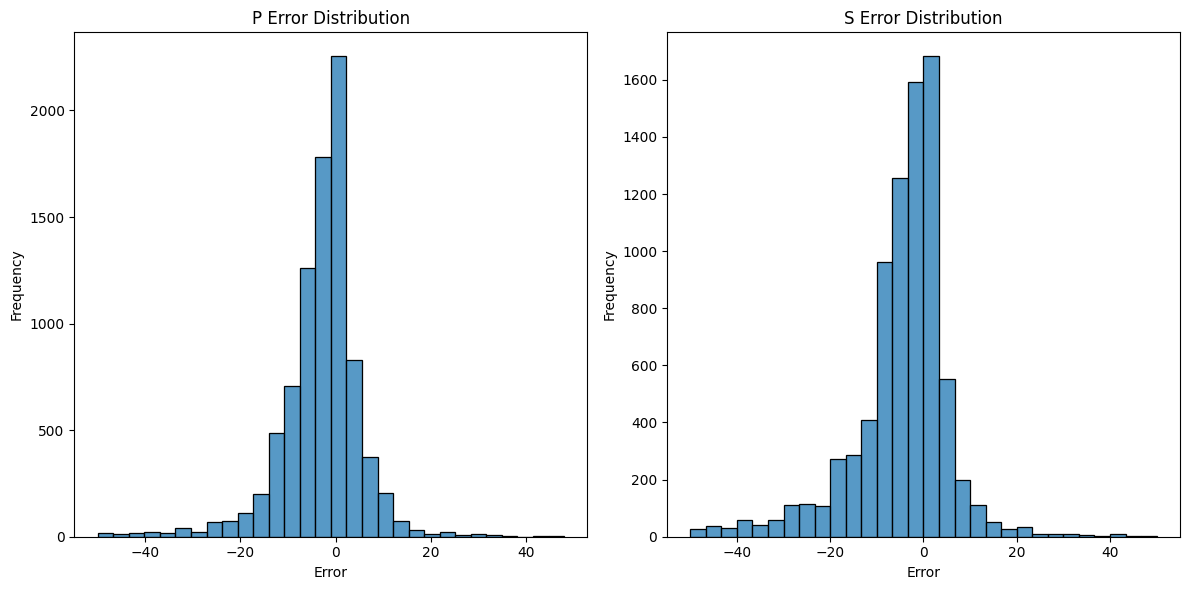

In [152]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# MOE

In [153]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/DiTing_Predict/DiTing_Moe/picks.csv')

# phasenet=phasenet.loc[:130000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [154]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,782603.0131_EV,earthquake_local,946,1280,945,1333.0,1,-53.0
1,864490.0803_EV,earthquake_local,1698,2508,1700,2531.0,-2,-23.0
2,597411.0062_EV,earthquake_local,1088,1242,1198,NaN,-110,NaN
3,811198.0153_EV,earthquake_local,1194,1361,1122,1367.0,72,-6.0
4,570269.0147_EV,earthquake_local,936,996,897,3555.0,39,-2559.0
...,...,...,...,...,...,...,...,...
10673,600997.0003_EV,earthquake_local,869,1070,966,NaN,-97,NaN
10674,864274.0272_EV,earthquake_local,1180,1745,1160,1936.0,20,-191.0
10675,598999.0056_EV,earthquake_local,1500,2230,1505,2248.0,-5,-18.0
10676,806152.0014_EV,earthquake_local,1696,2246,864,NaN,832,NaN


In [155]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 50
TP_threshold_S = 50
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_P, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['p_error']) > TP_threshold_P, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_S, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算FP的数量
#计算FP的数量
p_FP_count = 11000-result_moe['p_TP'].sum() - result_moe['p_FN'].sum()
s_FP_count = 10000 -result_moe['s_TP'].sum() - result_moe['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(stead)*0.2 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(stead)*0.2 - len(phasenet['s_idx'])-phasenet['s_idx'].isna().sum()
#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum() + phasenet['p_idx'].isna().sum()
s_FN= result_moe['s_FN'].sum() + phasenet['s_idx'].isna().sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_eqt = pd.DataFrame({
    'EQT': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']] = (
    result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 6852
P-FP: 322
P-FN: 3826
P-Precision: 0.9551156955673265
P-Recall: 0.6416932009739652
P-F1 Score: 0.7676450817835537
P-MAE: 0.1457326328079393
P-STD: 0.15368598982570775
S-TP: 6022
S-FP: 1311
S-FN: 4656
S-Precision: 0.821219146324833
S-Recall: 0.5639632890054317
S-F1 Score: 0.6687024596080173
S-MAE: 0.14273995350381932
S-STD: 0.13777338855639695


/tmp/ipykernel_1205417/1848987688.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_1205417/1848987688.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_1205417/1848987688.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col

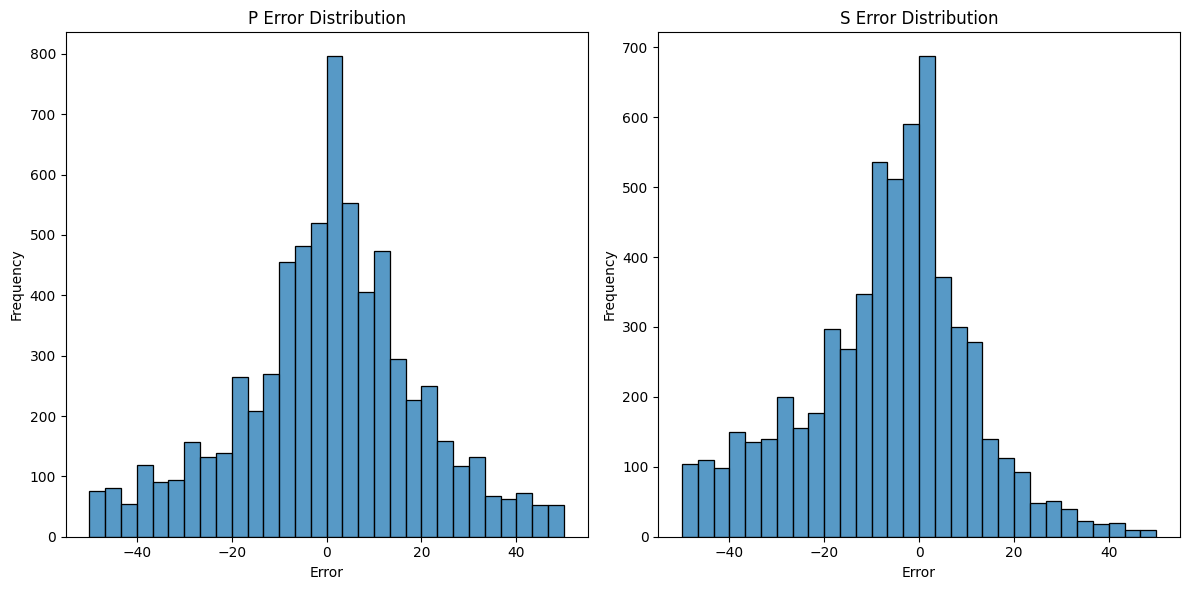

In [156]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# PhaseNet

In [157]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/DiTing_Predict/DiTing_PhaseNet/picks.csv')
# phasenet=phasenet.loc[:10000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [158]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,600555.0003_EV,earthquake_local,625,761,790,NaN,-165,NaN
1,807433.0343_EV,earthquake_local,1810,2567,1826,NaN,-16,NaN
2,806232.0412_EV,earthquake_local,1858,2551,2566,NaN,-708,NaN
3,864624.0356_EV,earthquake_local,929,1232,1251,NaN,-322,NaN
4,571051.0502_EV,earthquake_local,1812,2812,13,2833.0,1799,-21.0
...,...,...,...,...,...,...,...,...
42472,689812.0003_EV,earthquake_local,698,928,951,NaN,-253,NaN
42473,569308.0551_EV,earthquake_local,1138,1682,1,NaN,1137,NaN
42474,689421.1074_EV,earthquake_local,2120,2940,2,6.0,2118,2934.0
42475,602223.0028_EV,earthquake_local,890,1012,902,1031.0,-12,-19.0


In [159]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 50
TP_threshold_S = 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_S, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_phasenet.loc[:, 'p_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)
result_phasenet.loc[:, 's_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count =10000- result_phasenet['p_TP'].sum() -result_phasenet['p_FN'].sum()*0.1
s_FP_count =10000- result_phasenet['s_TP'].sum() -result_phasenet['s_FN'].sum()*0.1
# p_FP_count = result['p_FP'].sum() + len(phasenet)*0.2 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(phasenet)*0.2 - len(phasenet['s_idx'])-phasenet['s_idx'].isna().sum()

#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()*0.1
s_FN= result_phasenet['s_FN'].sum()*0.1

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

#将结果做成一个表格
result_table_phasenet = pd.DataFrame({
    'PhaseNet': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']] = (
    result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 5830
P-FP: 505.2999999999997
P-FN: 3664.7000000000003
P-Precision: 0.9202405568797059
P-Recall: 0.6140267728311584
P-F1 Score: 0.7365761212886924
P-MAE: 0.14532418524871354
P-STD: 0.06673478566368564
S-TP: 8047
S-FP: 969.8
S-FN: 983.2
S-Precision: 0.8924452133794695
S-Recall: 0.8911209054063032
S-F1 Score: 0.8917825677397905
S-MAE: 0.1422679259351311
S-STD: 0.07575529261470976


/tmp/ipykernel_1205417/1570626322.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_1205417/1570626322.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_1205417/1570626322.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using 

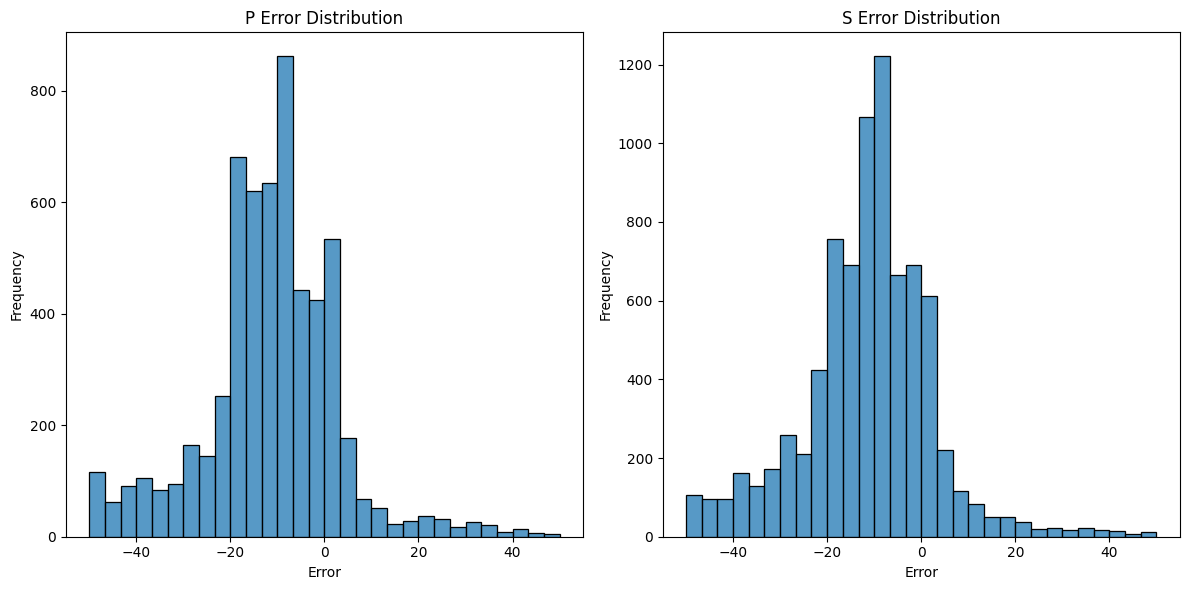

In [160]:

import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
data=result_phasenet[result_phasenet['p_TP'] == 1]['p_error']

sns.histplot(result_phasenet[result_phasenet['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_phasenet[result_phasenet['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# Results

In [161]:
import pandas as pd

# 1) 以 EQT 表举例
df_eqt = result_table_eqt.set_index('EQT')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('EQT', col) for col in df_eqt.columns])

# 2) Moe 表同理
df_moe = result_table_moe.set_index('Moe')
df_moe.columns = pd.MultiIndex.from_tuples([('Moe', col) for col in df_moe.columns])

# 3) PhaseNet 表
df_phasenet = result_table_phasenet.set_index('PhaseNet')
df_phasenet.columns = pd.MultiIndex.from_tuples([('PhaseNet', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_moe,df_eqt, df_phasenet], axis=1)

print('-------------------------------------stead--------------------------------------------')
df_multi


-------------------------------------stead--------------------------------------------


Moe                       EQT                  PhaseNet  \
                     P            S            P            S            P   
TP         8687.000000  8059.000000  6852.000000  6022.000000  5830.000000   
FP          317.000000   663.000000   322.000000  1311.000000   505.000000   
FN          996.000000  1278.000000  3826.000000  4656.000000  3664.000000   
Precision     0.964793     0.923985     0.955116     0.821219     0.920241   
Recall        0.897139     0.863125     0.641693     0.563963     0.614027   
F1 Score      0.929737     0.892519     0.767645     0.668702     0.736576   
MAE           0.133436     0.165594     0.145733     0.142740     0.145324   
STD           0.122058     0.144600     0.153686     0.137773     0.066735   

                        
                     S  
TP         8047.000000  
FP          969.000000  
FN          983.000000  
Precision     0.892445  
Recall        0.891121  
F1 Score      0.891783  
MAE           0.142268  
STD           0.075755

# figure

In [162]:
# import h5py
# import pandas as pd
# import matplotlib.pyplot as plt
# import os

# # 输入路径
# hd = '/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
# output_dir = '/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/Figure/output_waveforms_STEAD/'
# os.makedirs(output_dir, exist_ok=True)

# # ===== 读取数据并求交集 =====
# # 筛选 P/S 都为 TP 的 trace_name
# eqt_tp = result_eqt[(result_eqt['p_TP'] == 1) & (result_eqt['s_TP'] == 1)]['trace_name']
# moe_tp = result_moe[(result_moe['p_TP'] == 1) & (result_moe['s_TP'] == 1)]['trace_name']
# phasenet_tp = result_phasenet[(result_phasenet['p_TP'] == 1) & (result_phasenet['s_TP'] == 1)]['trace_name']
# common_traces = set(eqt_tp) & set(moe_tp) & set(phasenet_tp)

# # 筛选出三组数据对应的行
# df_eqt = result_eqt[result_eqt['trace_name'].isin(common_traces)].copy()
# df_moe = result_moe[result_moe['trace_name'].isin(common_traces)].copy()
# df_phasenet = result_phasenet[result_phasenet['trace_name'].isin(common_traces)].copy()

# # 设置索引，便于 trace_name 访问
# moe_dict = df_moe.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# phasenet_dict = df_phasenet.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# df_eqt=df_eqt.sample(n=100,random_state=42).copy()
# # ===== 读取波形并绘图 =====
# with h5py.File(hd, 'r') as f:
#     for i, row in df_eqt.iterrows():
#         if row['trace_category'] == 'noise':
#             continue

#         trace_name = row['trace_name']
#         try:
#             data = f['data'][trace_name][()]  # shape: (3, 6000)
#         except KeyError:
#             print(f"[WARN] Missing trace: {trace_name}")
#             continue

#         z, n, e = data[:,0], data[:,1], data[:,2]

#         p_arrival = row['p_arrival_sample']
#         s_arrival = row['s_arrival_sample']
#         p_eqt = row['p_idx']
#         s_eqt = row['s_idx']
#         p_moe = moe_dict[trace_name]['p_idx']
#         s_moe = moe_dict[trace_name]['s_idx']
#         p_phase = phasenet_dict[trace_name]['p_idx']
#         s_phase = phasenet_dict[trace_name]['s_idx']

#         fig, axs = plt.subplots(5, 1, figsize=(12, 10), sharex=False)
#         components = [z, n, e]
#         labels = ['Z', 'N', 'E']

#         for idx, (ax, comp, label) in enumerate(zip(axs[:3], components, labels)):
#             ax.plot(comp, label=f'{label} component')

#             # 到时标注
#             ax.axvline(p_arrival, color='green', linestyle='--', label='P Arrival')
#             ax.axvline(s_arrival, color='blue', linestyle='--', label='S Arrival')
#             ax.axvline(p_eqt, color='red', linestyle=':', label='EQT P')
#             ax.axvline(s_eqt, color='purple', linestyle=':', label='EQT S')
#             ax.axvline(p_moe, color='orange', linestyle=':', label='Moe P')
#             ax.axvline(s_moe, color='brown', linestyle=':', label='Moe S')
#             ax.axvline(p_phase, color='pink', linestyle='--', label='PhaseNet P')
#             ax.axvline(s_phase, color='cyan', linestyle='--', label='PhaseNet S')

#             ax.set_ylabel(label)
#             ax.legend(loc='upper right', fontsize=8)

#         # 第四图：P 波放大图（Z）
#         start_p = max(0, int(min(p_arrival, p_eqt, p_moe, p_phase) - 50))
#         end_p = min(6000, int(max(p_arrival, p_eqt, p_moe, p_phase) + 50))
#         axs[3].plot(z[start_p:end_p], label='Z (P Zoom)')
#         axs[3].axvline(p_arrival - start_p, color='black', linestyle='--', label='P Arrival')
#         axs[3].axvline(p_eqt - start_p, color='green', linestyle=':', label='EQT P')
#         axs[3].axvline(p_moe - start_p, color='red', linestyle=':', label='Moe P')
#         axs[3].axvline(p_phase - start_p, color='orange', linestyle='--', label='PhaseNet P')
#         axs[3].legend(loc='upper right', fontsize=8)
#         axs[3].set_ylabel('Z (P Zoom)')

#         # 第五图：S 波放大图（Z）
#         start_s = max(0, int(min(s_arrival, s_eqt, s_moe, s_phase) - 50))
#         end_s = min(6000, int(max(s_arrival, s_eqt, s_moe, s_phase) + 50))
#         axs[4].plot(z[start_s:end_s], label='Z (S Zoom)')
#         axs[4].axvline(s_arrival - start_s, color='black', linestyle='--', label='S Arrival')
#         axs[4].axvline(s_eqt - start_s, color='green', linestyle=':', label='EQT S')
#         axs[4].axvline(s_moe - start_s, color='red', linestyle=':', label='Moe S')
#         axs[4].axvline(s_phase - start_s, color='orange', linestyle='--', label='PhaseNet S')
#         axs[4].legend(loc='upper right', fontsize=8)
#         axs[4].set_ylabel('Z (S Zoom)')

#         # 保存图像
#         fig.suptitle(f'Trace: {trace_name}', fontsize=14)
#         plt.tight_layout(rect=[0, 0.03, 1, 0.95])
#         out_path = os.path.join(output_dir, f'{trace_name}.png')
#         plt.savefig(out_path)
#         plt.close(fig)
